## 1. Imports, đường dẫn và cấu hình

Notebook dùng toàn bộ dataset IMDb, split 60/20/20.

In [8]:
pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from pathlib import Path
import copy
import html
import re
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

try:
    import torch
    from torch import nn
    from torch.nn.utils.rnn import pack_padded_sequence
    from torch.utils.data import DataLoader, Dataset
except ImportError as error:
    raise ImportError(
        "Môi trường chưa có PyTorch. Cài bằng: python -m pip install torch"
    ) from error

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20

MAX_VOCAB_SIZE = 30_000
MIN_WORD_FREQUENCY = 2
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
BATCH_SIZE = 128
MAX_EPOCHS = 5
LEARNING_RATE = 1e-3
EARLY_STOPPING_PATIENCE = 2
GRADIENT_CLIP_NORM = 1.0

BASE_MAX_LENGTH = 100
LENGTH_VALUES = (50, 100, 200)
PAD_ID = 0
UNK_ID = 1

CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "lab05":
    LAB_DIR = CURRENT_DIR
elif (CURRENT_DIR / "lab05" / "W5.pdf").exists():
    LAB_DIR = CURRENT_DIR / "lab05"
elif (CURRENT_DIR.parent / "lab05" / "W5.pdf").exists():
    LAB_DIR = CURRENT_DIR.parent / "lab05"
else:
    raise FileNotFoundError(
        "Không tìm thấy thư mục lab05. Hãy mở notebook từ thư mục NLP hoặc lab05."
    )

PROJECT_DIR = LAB_DIR.parent
DATA_PATH = PROJECT_DIR / "data" / "IMDB Dataset.csv"
RESULTS_PATH = LAB_DIR / "results.csv"
LEARNING_CURVES_PATH = LAB_DIR / "learning_curves.png"
CONFUSION_MATRIX_PATH = LAB_DIR / "confusion_matrix.png"
SEQUENCE_LENGTH_PLOT_PATH = LAB_DIR / "sequence_length_experiment.png"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy dataset: {DATA_PATH}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"Thiết bị đang dùng: {DEVICE}")
print(f"Đường dẫn dataset: {DATA_PATH}")
print(f"PyTorch version: {torch.__version__}")


Thiết bị đang dùng: cpu
Đường dẫn dataset: C:\Users\KIEN\OneDrive\Máy tính\NLP\data\IMDB Dataset.csv
PyTorch version: 2.14.1+cpu


## 2. Đọc IMDb và kiểm tra cột

Kiểm tra cấu trúc file trước khi xử lý. Dataset dùng cột review và sentiment.

In [10]:
TEXT_COLUMN = "review"
LABEL_COLUMN = "sentiment"

raw_df = pd.read_csv(DATA_PATH, encoding="utf-8")
required_columns = {TEXT_COLUMN, LABEL_COLUMN}
missing_columns = required_columns - set(raw_df.columns)
if missing_columns:
    raise KeyError(
        f"Thiếu cột {sorted(missing_columns)}. Cột hiện có: {list(raw_df.columns)}"
    )

print(f"Số dòng ban đầu: {len(raw_df):,}")
display(raw_df[[TEXT_COLUMN, LABEL_COLUMN]].head(3))


Số dòng ban đầu: 50,000


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


## 3. Làm sạch tối thiểu và kiểm tra bản ghi

Chuẩn hóa HTML, chữ thường và khoảng trắng; giữ từ phủ định. Loại dòng thiếu, review rỗng, nội dung trùng nhưng nhãn mâu thuẫn; với duplicate cùng nhãn thì chỉ giữ một bản để tránh leakage giữa các split.

In [11]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?", flags=re.IGNORECASE)

def normalize_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

data = raw_df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
missing_text_count = int(data[TEXT_COLUMN].isna().sum())
missing_label_count = int(data[LABEL_COLUMN].isna().sum())
data = data.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()

data[TEXT_COLUMN] = data[TEXT_COLUMN].map(normalize_review)
data[LABEL_COLUMN] = data[LABEL_COLUMN].astype(str).str.strip().str.lower()
data = data[data[TEXT_COLUMN].str.len() > 0].copy()
data = data[data[TEXT_COLUMN].map(lambda text: len(tokenize(text)) > 0)].copy()

unexpected_labels = set(data[LABEL_COLUMN].unique()) - {"positive", "negative"}
if unexpected_labels:
    raise ValueError(f"Nhãn ngoài dự kiến: {unexpected_labels}")

label_count_per_text = data.groupby(TEXT_COLUMN)[LABEL_COLUMN].nunique()
conflicting_texts = set(label_count_per_text[label_count_per_text > 1].index)
conflicting_rows_removed = int(data[TEXT_COLUMN].isin(conflicting_texts).sum())
data = data[~data[TEXT_COLUMN].isin(conflicting_texts)].copy()

duplicate_rows_removed = int(data[TEXT_COLUMN].duplicated().sum())
data = data.drop_duplicates(subset=[TEXT_COLUMN], keep="first").reset_index(drop=True)

data["label_id"] = data[LABEL_COLUMN].map({"negative": 0, "positive": 1}).astype(int)
data["token_length"] = data[TEXT_COLUMN].map(lambda text: len(tokenize(text)))

cleaning_summary = pd.DataFrame([{
    "Số dòng ban đầu": len(raw_df),
    "Review thiếu": missing_text_count,
    "Nhãn thiếu": missing_label_count,
    "Dòng bị bỏ vì nội dung/nhãn mâu thuẫn": conflicting_rows_removed,
    "Dòng trùng cùng nhãn đã bỏ": duplicate_rows_removed,
    "Số dòng sau làm sạch": len(data),
}])
display(cleaning_summary)


,Số dòng ban đầu,Review thiếu,Nhãn thiếu,Dòng bị bỏ vì nội dung/nhãn mâu thuẫn,Dòng trùng cùng nhãn đã bỏ,Số dòng sau làm sạch
0,50000,0,0,0,422,49578


## 4. Experiment 1 — Dataset inspection

Xem số mẫu từng lớp và độ dài chuỗi. Histogram hiển thị toàn bộ miền độ dài; bảng có min, median, mean, max để làm cơ sở chọn max_length.

In [12]:
class_distribution = (
    data[LABEL_COLUMN]
    .value_counts()
    .rename_axis("Nhãn")
    .reset_index(name="Số review")
)
class_distribution["Tỷ lệ (%)"] = (
    100 * class_distribution["Số review"] / class_distribution["Số review"].sum()
)
display(class_distribution)

length_summary = data["token_length"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("Số token").T
display(length_summary)

print(f"Độ dài chuỗi nhỏ nhất: {data['token_length'].min()}")
print(f"Độ dài chuỗi trung vị: {data['token_length'].median():.1f}")
print(f"Độ dài chuỗi trung bình: {data['token_length'].mean():.1f}")
print(f"Độ dài chuỗi lớn nhất: {data['token_length'].max()}")


,Nhãn,Số review,Tỷ lệ (%)
0,positive,24882,50.187583
1,negative,24696,49.812417


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Số token,49578.0,231.205958,171.090937,6.0,127.0,173.0,280.0,451.3,589.0,903.0,2473.0


Độ dài chuỗi nhỏ nhất: 6
Độ dài chuỗi trung vị: 173.0
Độ dài chuỗi trung bình: 231.2
Độ dài chuỗi lớn nhất: 2473


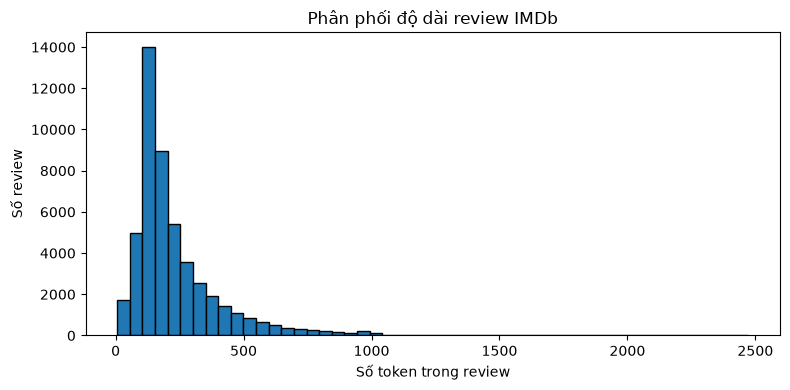

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(data["token_length"], bins=50, edgecolor="black")
plt.xlabel("Số token trong review")
plt.ylabel("Số review")
plt.title("Phân phối độ dài review IMDb")
plt.tight_layout()
plt.show()


**Nhận xét — Experiment 1**
Sau khi làm sạch còn 49.578 review; trung vị là 173 token, phân vị 90% là 451 token và phân vị 95% là 589 token. Nếu muốn giữ gần 90% review không bị cắt, có thể cân nhắc max_length khoảng 451. Trong ba giá trị đề yêu cầu, 200 giữ được nhiều token nhất (68,70%) và cho F1 tốt nhất ở thí nghiệm độ dài, nhưng vẫn truncate 40,92% review. Vì vậy 200 là lựa chọn tốt nhất trong các giá trị đã thử, chưa thể xem là tối ưu chung.

## 5. Chia train / validation / test

Chia stratified 60/20/20 để giữ tỷ lệ lớp tương tự giữa các tập. Vocabulary sẽ chỉ được học từ train.

In [14]:
texts = data[TEXT_COLUMN].tolist()
labels = data["label_id"].to_numpy(dtype=np.int64)

x_train_val, x_test, y_train_val, y_test = train_test_split(
    texts,
    labels,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=labels,
)
relative_validation_size = VALIDATION_SIZE / (1 - TEST_SIZE)
x_train, x_validation, y_train, y_validation = train_test_split(
    x_train_val,
    y_train_val,
    test_size=relative_validation_size,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

split_sizes = pd.DataFrame([
    {"Tập": "Train", "Số mẫu": len(x_train)},
    {"Tập": "Validation", "Số mẫu": len(x_validation)},
    {"Tập": "Test", "Số mẫu": len(x_test)},
])
display(split_sizes)

split_distribution_rows = []
for split_name, split_labels in [
    ("Train", y_train),
    ("Validation", y_validation),
    ("Test", y_test),
]:
    proportions = pd.Series(split_labels).value_counts(normalize=True)
    for label_id, proportion in proportions.items():
        split_distribution_rows.append({
            "Tập": split_name,
            "Nhãn": "positive" if label_id == 1 else "negative",
            "Tỷ lệ (%)": proportion * 100,
        })
display(pd.DataFrame(split_distribution_rows))


,Tập,Số mẫu
0,Train,29746
1,Validation,9916
2,Test,9916


,Tập,Nhãn,Tỷ lệ (%)
0,Train,positive,50.184899
1,Train,negative,49.815101
2,Validation,positive,50.191610
3,Validation,negative,49.808390
4,Test,positive,50.191610
5,Test,negative,49.808390


## 6. Experiment 1 — Tạo vocabulary từ train

Dùng word-level tokenizer, giới hạn vocabulary để giảm bộ nhớ. ID 0 dành cho PAD, ID 1 dành cho UNK. Không xem nội dung validation/test khi tạo vocabulary.

In [15]:
word_counts = Counter()
for review in x_train:
    word_counts.update(tokenize(review))

vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for word, count in word_counts.most_common():
    if count < MIN_WORD_FREQUENCY:
        break
    if len(vocab) >= MAX_VOCAB_SIZE:
        break
    vocab[word] = len(vocab)

id_to_word = {index: word for word, index in vocab.items()}
VOCAB_SIZE = len(vocab)

print(f"Số token duy nhất trong train trước giới hạn: {len(word_counts):,}")
print(f"Kích thước vocabulary gồm PAD/UNK: {VOCAB_SIZE:,}")
display(pd.DataFrame(
    word_counts.most_common(10),
    columns=["Token phổ biến trong train", "Số lần"],
))


Số token duy nhất trong train trước giới hạn: 89,947
Kích thước vocabulary gồm PAD/UNK: 30,000


,Token phổ biến trong train,Số lần
0,the,399200
1,and,193466
2,a,192815
3,of,172813
4,to,160193
5,is,125612
6,in,111454
7,it,93413
8,i,92583
9,this,89949


In [16]:
sample_review = x_train[0]
sample_tokens = tokenize(sample_review)
sample_ids = [vocab.get(token, UNK_ID) for token in sample_tokens[:20]]

display(pd.DataFrame({
    "Token": sample_tokens[:20],
    "Token ID": sample_ids,
}))
print("Đoạn review mẫu:")
print(sample_review[:500])


,Token,Token ID
0,no,54
1,holds,1736
2,barred,12256
3,is,7
4,a,4
5,movie,16
6,that,12
7,should,141
8,in,8
9,no,54


Đoạn review mẫu:
no holds barred is a movie that should in no way ever be taken seriously. it sucks hardcore as a serious movie. look at it more in the way that you should plan 9 from outer space. they are one in the same in that they are both so bad they are funny. the funny moments in no holds barred are usually the ones that aren't supposed to be. when rip (played by hulk hogan as only he can play them) grabs the limo driver out of the front after his first meeting with brell (kurt fuller) hilarity ensues and


## 7. Padding và truncation

Mã hóa tới độ dài lớn nhất dùng trong thí nghiệm (200). Với mỗi giá trị nhỏ hơn, lấy phần đầu chuỗi và pad phần còn lại bằng PAD. Độ dài thật được truyền riêng để RNN bỏ qua padding.

In [17]:
MAX_STORED_LENGTH = max(LENGTH_VALUES)

def encode_reviews(review_list, vocabulary, max_length):
    encoded = np.zeros((len(review_list), max_length), dtype=np.int32)
    lengths = np.zeros(len(review_list), dtype=np.int32)

    for row_index, review in enumerate(review_list):
        tokens = tokenize(review)[:max_length]
        token_ids = [vocabulary.get(token, UNK_ID) for token in tokens]
        lengths[row_index] = len(token_ids)
        if token_ids:
            encoded[row_index, :len(token_ids)] = token_ids

    return encoded, lengths

x_train_ids, train_lengths = encode_reviews(
    x_train, vocab, MAX_STORED_LENGTH
)
x_validation_ids, validation_lengths = encode_reviews(
    x_validation, vocab, MAX_STORED_LENGTH
)
x_test_ids, test_lengths = encode_reviews(
    x_test, vocab, MAX_STORED_LENGTH
)

print("Shape train IDs:", x_train_ids.shape)
print("Shape validation IDs:", x_validation_ids.shape)
print("Shape test IDs:", x_test_ids.shape)


Shape train IDs: (29746, 200)
Shape validation IDs: (9916, 200)
Shape test IDs: (9916, 200)


## 8. Experiment 2 — So sánh max_length 50/100/200

Tỷ lệ token được giữ tính bằng tổng số token sau truncation chia cho tổng số token ban đầu. Padding không được tính là token ngôn ngữ.

In [18]:
all_token_lengths = data["token_length"].to_numpy(dtype=np.int64)
total_original_tokens = int(all_token_lengths.sum())

length_preparation_rows = []
for max_length in LENGTH_VALUES:
    retained_tokens = int(np.minimum(all_token_lengths, max_length).sum())
    length_preparation_rows.append({
        "Max length": max_length,
        "Token giữ lại (%)": 100 * retained_tokens / total_original_tokens,
        "Review bị truncate (%)": 100 * np.mean(all_token_lengths > max_length),
        "Review cần padding (%)": 100 * np.mean(all_token_lengths < max_length),
    })

length_preparation_table = pd.DataFrame(length_preparation_rows)
display(length_preparation_table)


,Max length,Token giữ lại (%),Review bị truncate (%),Review cần padding (%)
0,50,21.532926,97.535197,2.285288
1,100,41.593978,87.639679,12.146517
2,200,68.700560,40.915325,58.765985


**Nhận xét — Experiment 2**

Trong lần chạy này, tăng max_length 50 → 100 → 200 đi kèm test F1 macro tăng 0,7654 → 0,8115 → 0,8466. Tỷ lệ token giữ lại tăng 21,53% → 41,59% → 68,70%; tuy nhiên thời gian train tăng 57,5 → 157,9 → 793,8 giây. Kết quả này cho thấy lợi ích của ngữ cảnh dài hơn trong thí nghiệm hiện tại, nhưng không chứng minh tăng độ dài luôn tăng performance. Nếu cắt quá sớm có thể mất phần kết luận, phủ định hoặc ý chuyển hướng xuất hiện về sau.

## 9. Core implementation — SimpleRNNCell

Cài một timestep bằng NumPy trong rnn_cell.py, sau đó dùng cùng trọng số với torch.nn.RNNCell để so sánh kết quả.

In [19]:
sys.path.insert(0, str(LAB_DIR))
from rnn_cell import SimpleRNNCell

fixed_w_xh = np.array([[0.5, 0.2], [0.1, 0.4]], dtype=np.float64)
fixed_w_hh = np.array([[0.3, 0.1], [0.2, 0.5]], dtype=np.float64)
fixed_b_h = np.array([0.0, 0.0], dtype=np.float64)
x_t = np.array([1.0, 0.0], dtype=np.float64)
h_previous = np.array([0.5, 0.2], dtype=np.float64)

numpy_cell = SimpleRNNCell(input_size=2, hidden_size=2)
numpy_cell.W_xh = fixed_w_xh.copy()
numpy_cell.W_hh = fixed_w_hh.copy()
numpy_cell.b_h = fixed_b_h.copy()
numpy_hidden = numpy_cell.forward(x_t, h_previous)

torch_cell = nn.RNNCell(input_size=2, hidden_size=2, bias=True)
with torch.no_grad():
    torch_cell.weight_ih.copy_(torch.tensor(fixed_w_xh, dtype=torch.float32))
    torch_cell.weight_hh.copy_(torch.tensor(fixed_w_hh, dtype=torch.float32))
    torch_cell.bias_ih.copy_(torch.tensor(fixed_b_h, dtype=torch.float32))
    torch_cell.bias_hh.zero_()

torch_hidden = torch_cell(
    torch.tensor(x_t, dtype=torch.float32).unsqueeze(0),
    torch.tensor(h_previous, dtype=torch.float32).unsqueeze(0),
).squeeze(0).detach().numpy()

display(pd.DataFrame({
    "Thành phần": ["NumPy", "torch.nn.RNNCell", "Sai khác tuyệt đối lớn nhất"],
    "Giá trị": [
        numpy_hidden.tolist(),
        torch_hidden.tolist(),
        float(np.max(np.abs(numpy_hidden - torch_hidden))),
    ],
}))


,Thành phần,Giá trị
0,NumPy,"[0.5849798828807287, 0.29131261245159096]"
1,torch.nn.RNNCell,"[0.5849798917770386, 0.29131263494491577]"
2,Sai khác tuyệt đối lớn nhất,0.0


**Nhận xét — RNN cell**

Hai vector hidden state NumPy và torch.nn.RNNCell gần như trùng nhau: xấp xỉ [0,58498; 0,29131]. Điều này phù hợp với việc cả hai cùng tính tanh(W_xh x_t + W_hh h_(t-1) + b_h). Output đang ghi sai khác tuyệt đối lớn nhất là 0,0, nhưng các số lẻ được in ra lệch nhau cỡ 10^-8 do độ chính xác số thực; có thể kiểm tra lại cell nếu cần báo cáo sai khác chính xác.

## 10. Metrics và tiện ích đánh giá

Nhãn positive được mã hóa là 1. Báo cáo precision/recall/F1 của positive và macro F1 để nhìn cả hai lớp.

In [20]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_positive": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "recall_positive": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "f1_positive": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())

def make_result_row(
    model_name,
    architecture,
    representation,
    split,
    metrics,
    max_length=np.nan,
    validation_loss=np.nan,
    training_seconds=np.nan,
    epochs_trained=np.nan,
    parameters=np.nan,
    vocabulary_size=np.nan,
    tokens_retained_percent=np.nan,
    peak_memory_mb=np.nan,
    notes="",
):
    return {
        "model": model_name,
        "architecture": architecture,
        "representation": representation,
        "max_length": max_length,
        "split": split,
        **metrics,
        "validation_loss": validation_loss,
        "training_time_seconds": training_seconds,
        "epochs_trained": epochs_trained,
        "parameters": parameters,
        "vocabulary_size": vocabulary_size,
        "tokens_retained_percent": tokens_retained_percent,
        "peak_memory_mb": peak_memory_mb,
        "notes": notes,
    }

candidate_models = {}
sequence_length_results = {}


## 11. Experiment 3 — Baseline TF-IDF + Logistic Regression

Fit vectorizer/classifier trên train; theo dõi validation để so sánh. Test chỉ dùng ở phần đánh giá cuối.

In [21]:
tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1),
        min_df=1,
        stop_words=None,
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

started = time.perf_counter()
tfidf_pipeline.fit(x_train, y_train)
tfidf_training_seconds = time.perf_counter() - started

tfidf_validation_predictions = tfidf_pipeline.predict(x_validation)
tfidf_validation_metrics = calculate_metrics(
    y_validation, tfidf_validation_predictions
)
tfidf_vocabulary_size = len(
    tfidf_pipeline.named_steps["tfidf"].vocabulary_
)
tfidf_parameters = (
    tfidf_pipeline.named_steps["classifier"].coef_.size
    + tfidf_pipeline.named_steps["classifier"].intercept_.size
)

candidate_models["TF-IDF + Logistic Regression"] = {
    "kind": "tfidf",
    "model": tfidf_pipeline,
    "architecture": "Logistic Regression",
    "validation_metrics": tfidf_validation_metrics,
    "validation_row": make_result_row(
        "TF-IDF + Logistic Regression",
        "Logistic Regression",
        "TF-IDF unigram",
        "validation",
        tfidf_validation_metrics,
        training_seconds=tfidf_training_seconds,
        parameters=tfidf_parameters,
        vocabulary_size=tfidf_vocabulary_size,
        notes="Fit vectorizer chỉ trên train.",
    ),
}

display(pd.DataFrame([{
    "Model": "TF-IDF + Logistic Regression",
    "Vocabulary size": tfidf_vocabulary_size,
    "Validation accuracy": tfidf_validation_metrics["accuracy"],
    "Validation precision positive": tfidf_validation_metrics["precision_positive"],
    "Validation recall positive": tfidf_validation_metrics["recall_positive"],
    "Validation F1 macro": tfidf_validation_metrics["f1_macro"],
    "Thời gian train (giây)": tfidf_training_seconds,
    "Số tham số classifier": tfidf_parameters,
}]))


,Model,Vocabulary size,Validation accuracy,Validation precision positive,Validation recall positive,Validation F1 macro,Thời gian train (giây),Số tham số classifier
0,TF-IDF + Logistic Regression,82646,0.89401,0.88445,0.907374,0.89398,6.139227,82647


## 12. Sequence classifier và DataLoader

RNN/LSTM/GRU cùng dùng embedding, hidden size và linear output. Packed sequence giúp cell không cập nhật state trên các vị trí padding.

In [22]:
class ReviewSequenceDataset(Dataset):
    def __init__(self, encoded_reviews, sequence_lengths, targets, max_length):
        self.tokens = torch.as_tensor(
            encoded_reviews[:, :max_length].astype(np.int64, copy=False)
        )
        self.lengths = torch.as_tensor(
            np.minimum(sequence_lengths, max_length).astype(np.int64)
        )
        self.targets = torch.as_tensor(
            np.asarray(targets, dtype=np.float32)
        )
        if torch.any(self.lengths <= 0):
            raise ValueError("Có review không còn token sau tiền xử lý.")

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.tokens[index], self.lengths[index], self.targets[index]

def make_loaders(max_length):
    train_dataset = ReviewSequenceDataset(
        x_train_ids, train_lengths, y_train, max_length
    )
    validation_dataset = ReviewSequenceDataset(
        x_validation_ids, validation_lengths, y_validation, max_length
    )
    test_dataset = ReviewSequenceDataset(
        x_test_ids, test_lengths, y_test, max_length
    )

    generator = torch.Generator().manual_seed(RANDOM_STATE)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=generator,
        pin_memory=DEVICE.type == "cuda",
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )
    return train_loader, validation_loader, test_loader

class SequenceClassifier(nn.Module):
    def __init__(
        self,
        architecture,
        vocabulary_size,
        embedding_dim,
        hidden_size,
        pad_id,
    ):
        super().__init__()
        self.architecture = architecture
        self.embedding = nn.Embedding(
            vocabulary_size, embedding_dim, padding_idx=pad_id
        )
        recurrent_layers = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU,
        }
        if architecture not in recurrent_layers:
            raise ValueError(f"Kiến trúc không hỗ trợ: {architecture}")
        self.recurrent = recurrent_layers[architecture](
            input_size=embedding_dim,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, recurrent_state = self.recurrent(packed)
        if self.architecture == "LSTM":
            hidden_state = recurrent_state[0]
        else:
            hidden_state = recurrent_state
        last_hidden = hidden_state[-1]
        return self.classifier(last_hidden).squeeze(-1)


In [23]:
def evaluate_sequence_model(model, data_loader, loss_function):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_probabilities = []

    with torch.no_grad():
        for token_ids, lengths, targets in data_loader:
            token_ids = token_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(token_ids, lengths)
            batch_loss = loss_function(logits, targets)
            total_loss += batch_loss.item() * len(targets)
            all_targets.extend(targets.to(torch.int64).cpu().tolist())
            all_probabilities.extend(
                torch.sigmoid(logits).cpu().tolist()
            )

    probabilities = np.asarray(all_probabilities)
    predictions = (probabilities >= 0.5).astype(np.int64)
    metrics = calculate_metrics(
        np.asarray(all_targets, dtype=np.int64), predictions
    )
    average_loss = total_loss / len(data_loader.dataset)
    return average_loss, metrics, np.asarray(all_targets), predictions, probabilities

def train_sequence_model(architecture, max_length):
    torch.manual_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)

    train_loader, validation_loader, _ = make_loaders(max_length)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
        memory_before_bytes = torch.cuda.memory_allocated(DEVICE)
        torch.cuda.reset_peak_memory_stats(DEVICE)
    else:
        memory_before_bytes = 0
    model = SequenceClassifier(
        architecture=architecture,
        vocabulary_size=VOCAB_SIZE,
        embedding_dim=EMBEDDING_DIM,
        hidden_size=HIDDEN_SIZE,
        pad_id=PAD_ID,
    ).to(DEVICE)

    loss_function = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_validation_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    started = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_train_loss = 0.0

        for token_ids, lengths, targets in train_loader:
            token_ids = token_ids.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            logits = model(token_ids, lengths)
            loss = loss_function(logits, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=GRADIENT_CLIP_NORM
            )
            optimizer.step()
            total_train_loss += loss.item() * len(targets)

        train_loss = total_train_loss / len(train_loader.dataset)
        validation_loss, validation_metrics, _, _, _ = evaluate_sequence_model(
            model, validation_loader, loss_function
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_f1_macro": validation_metrics["f1_macro"],
        })
        print(
            f"Vòng {epoch}/{MAX_EPOCHS} | "
            f"loss train={train_loss:.4f} | "
            f"loss validation={validation_loss:.4f} | "
            f"F1 macro validation={validation_metrics['f1_macro']:.4f}"
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("Dừng sớm vì validation loss không cải thiện.")
            break

    training_seconds = time.perf_counter() - started
    if best_state is None:
        raise RuntimeError("Training không tạo được checkpoint hợp lệ.")
    model.load_state_dict(best_state)
    model.to(DEVICE)

    _, best_validation_metrics, _, _, _ = evaluate_sequence_model(
        model, validation_loader, loss_function
    )
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
        peak_memory_mb = (
            torch.cuda.max_memory_allocated(DEVICE) - memory_before_bytes
        ) / (1024 ** 2)
    else:
        peak_memory_mb = np.nan
    return {
        "model": model,
        "architecture": architecture,
        "max_length": max_length,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "epochs_trained": len(history),
        "training_seconds": training_seconds,
        "parameters": count_parameters(model),
        "peak_memory_mb": peak_memory_mb,
        "validation_metrics": best_validation_metrics,
        "validation_loss": best_validation_loss,
    }

def sequence_validation_row(run, model_name):
    retained_percent = 100 * np.minimum(
        all_token_lengths, run["max_length"]
    ).sum() / total_original_tokens
    return make_result_row(
        model_name,
        run["architecture"],
        "Embedding + " + run["architecture"],
        "validation",
        run["validation_metrics"],
        max_length=run["max_length"],
        validation_loss=run["validation_loss"],
        training_seconds=run["training_seconds"],
        epochs_trained=run["epochs_trained"],
        parameters=run["parameters"],
        vocabulary_size=VOCAB_SIZE,
        tokens_retained_percent=retained_percent,
        peak_memory_mb=run["peak_memory_mb"],
        notes=f"Best checkpoint ở epoch {run['best_epoch']}.",
    )


## 13. Experiment 3 — TF-IDF so với Simple RNN

Dùng max_length nền là 100 cho mô hình chuỗi. Cả hai mô hình dùng cùng train/validation/test split; so sánh validation trước.

In [24]:
rnn_run = train_sequence_model("RNN", BASE_MAX_LENGTH)
candidate_models["RNN + Embedding"] = {
    "kind": "sequence",
    "model": rnn_run["model"],
    "architecture": "RNN",
    "run": rnn_run,
    "validation_metrics": rnn_run["validation_metrics"],
    "validation_row": sequence_validation_row(
        rnn_run, "RNN + Embedding"
    ),
}

experiment3_table = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Representation": "TF-IDF unigram",
        "Validation accuracy": tfidf_validation_metrics["accuracy"],
        "Validation F1 macro": tfidf_validation_metrics["f1_macro"],
        "Training time (giây)": tfidf_training_seconds,
        "Số tham số": tfidf_parameters,
    },
    {
        "Model": "RNN + Embedding",
        "Representation": "Chuỗi token",
        "Validation accuracy": rnn_run["validation_metrics"]["accuracy"],
        "Validation F1 macro": rnn_run["validation_metrics"]["f1_macro"],
        "Training time (giây)": rnn_run["training_seconds"],
        "Số tham số": rnn_run["parameters"],
    },
])
display(experiment3_table)
display(rnn_run["history"])


Vòng 1/5 | loss train=0.6932 | loss validation=0.7046 | F1 macro validation=0.5026
Vòng 2/5 | loss train=0.6649 | loss validation=0.6387 | F1 macro validation=0.6448
Vòng 3/5 | loss train=0.6176 | loss validation=0.6156 | F1 macro validation=0.6773
Vòng 4/5 | loss train=0.5772 | loss validation=0.6052 | F1 macro validation=0.6899
Vòng 5/5 | loss train=0.5440 | loss validation=0.5724 | F1 macro validation=0.7314


,Model,Representation,Validation accuracy,Validation F1 macro,Training time (giây),Số tham số
0,TF-IDF + Logistic Regression,TF-IDF unigram,0.894010,0.893980,6.139227,82647
1,RNN + Embedding,Chuỗi token,0.731444,0.731372,64.466036,1928385


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.693240,0.704572,0.547499,0.502607
1,2,0.664948,0.638657,0.645018,0.644803
2,3,0.617602,0.615575,0.680214,0.677320
3,4,0.577156,0.605233,0.690904,0.689890
4,5,0.544005,0.572370,0.731444,0.731372


**Nhận xét — Experiment 3**

RNN xử lý token tuần tự nên có cơ chế để biểu diễn thứ tự; TF-IDF unigram không giữ thứ tự từ. Tuy nhiên, validation F1 macro của RNN là 0,7314, thấp hơn TF-IDF + Logistic Regression (0,8940). Trong lần chạy này, khả năng mô hình hóa chuỗi chưa đem lại kết quả phân loại tốt hơn; RNN có thể cần thêm dữ liệu, epoch hoặc tinh chỉnh. RNN cũng train khoảng 64,5 giây, so với 6,14 giây của baseline.

## 14. Experiment 4 — Train LSTM

Giữ vocabulary, embedding dimension, hidden size, batch size, optimizer, learning rate, số epoch và split như RNN. Chỉ đổi recurrent architecture.

In [25]:
lstm_run = train_sequence_model("LSTM", BASE_MAX_LENGTH)
candidate_models["LSTM + Embedding"] = {
    "kind": "sequence",
    "model": lstm_run["model"],
    "architecture": "LSTM",
    "run": lstm_run,
    "validation_metrics": lstm_run["validation_metrics"],
    "validation_row": sequence_validation_row(
        lstm_run, "LSTM + Embedding"
    ),
}
display(lstm_run["history"])


Vòng 1/5 | loss train=0.6718 | loss validation=0.6483 | F1 macro validation=0.5946
Vòng 2/5 | loss train=0.5603 | loss validation=0.5433 | F1 macro validation=0.7282
Vòng 3/5 | loss train=0.4560 | loss validation=0.4867 | F1 macro validation=0.7720
Vòng 4/5 | loss train=0.3847 | loss validation=0.4469 | F1 macro validation=0.7974
Vòng 5/5 | loss train=0.3233 | loss validation=0.4508 | F1 macro validation=0.8124


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.671844,0.648309,0.622529,0.594639
1,2,0.560300,0.543258,0.734470,0.728209
2,3,0.456007,0.486667,0.774203,0.771953
3,4,0.384743,0.446856,0.797398,0.797390
4,5,0.323331,0.450805,0.812424,0.812380


**Nhận xét — LSTM**

LSTM dùng cell state và các gate để điều tiết việc giữ/xóa thông tin qua nhiều timestep. Validation F1 macro của LSTM là 0,7974, cao hơn RNN (0,7314), phù hợp với dự đoán trong thí nghiệm này. Đổi lại, LSTM train khoảng 306,7 giây, so với 64,5 giây của RNN. Validation loss thấp nhất ở epoch 4 rồi tăng nhẹ ở epoch 5, nên checkpoint tốt nhất được lấy tại epoch 4.

## 15. Experiment 4 — Train GRU

Các điều kiện giữ nguyên; chỉ đổi recurrent architecture sang GRU.

In [26]:
gru_run = train_sequence_model("GRU", BASE_MAX_LENGTH)
candidate_models["GRU + Embedding"] = {
    "kind": "sequence",
    "model": gru_run["model"],
    "architecture": "GRU",
    "run": gru_run,
    "validation_metrics": gru_run["validation_metrics"],
    "validation_row": sequence_validation_row(
        gru_run, "GRU + Embedding"
    ),
}
display(gru_run["history"])


Vòng 1/5 | loss train=0.6640 | loss validation=0.5794 | F1 macro validation=0.7109
Vòng 2/5 | loss train=0.5131 | loss validation=0.4946 | F1 macro validation=0.7662
Vòng 3/5 | loss train=0.4126 | loss validation=0.4669 | F1 macro validation=0.7801
Vòng 4/5 | loss train=0.3448 | loss validation=0.4101 | F1 macro validation=0.8162
Vòng 5/5 | loss train=0.2891 | loss validation=0.4667 | F1 macro validation=0.8248


,epoch,train_loss,validation_loss,validation_accuracy,validation_f1_macro
0,1,0.663983,0.579376,0.711376,0.710891
1,2,0.513108,0.494568,0.768758,0.766240
2,3,0.412636,0.466907,0.782775,0.780138
3,4,0.344756,0.410057,0.816559,0.816240
4,5,0.289133,0.466744,0.825333,0.824802


In [27]:
architecture_rows = []
for name in [
    "RNN + Embedding",
    "LSTM + Embedding",
    "GRU + Embedding",
]:
    run = candidate_models[name]["run"]
    metrics = run["validation_metrics"]
    architecture_rows.append({
        "Model": name,
        "Parameters": run["parameters"],
        "Epochs trained": run["epochs_trained"],
        "Training time (giây)": run["training_seconds"],
        "Peak GPU memory (MB)": run["peak_memory_mb"],
        "Validation accuracy": metrics["accuracy"],
        "Validation precision": metrics["precision_positive"],
        "Validation recall": metrics["recall_positive"],
        "Validation F1 positive": metrics["f1_positive"],
        "Validation F1 macro": metrics["f1_macro"],
    })

architecture_comparison = pd.DataFrame(architecture_rows)
display(architecture_comparison.sort_values(
    "Validation F1 macro", ascending=False
))


,Model,Parameters,Epochs trained,Training time (giây),Peak GPU memory (MB),Validation accuracy,Validation precision,Validation recall,Validation F1 positive,Validation F1 macro
2,GRU + Embedding,1945025,5,157.923818,NaN,0.816559,0.795030,0.854933,0.823894,0.816240
1,LSTM + Embedding,1953345,5,306.712128,NaN,0.797398,0.804348,0.788025,0.796103,0.797390
0,RNN + Embedding,1928385,5,64.466036,NaN,0.731444,0.726774,0.745027,0.735787,0.731372


**Nhận xét — Experiment 4**

Trong ba recurrent model, GRU có validation F1 macro cao nhất (0,8162), tiếp theo là LSTM (0,7974) và RNN (0,7314). RNN có ít tham số nhất (1.928.385) và train nhanh nhất (64,5 giây); LSTM có 1.953.345 tham số và mất 306,7 giây; GRU có 1.945.025 tham số và mất 157,9 giây. Kết quả phù hợp một phần với dự đoán LSTM/GRU xử lý tốt hơn RNN thường, nhưng LSTM không đứng đầu. TF-IDF baseline vẫn có validation F1 macro 0,8940. Máy chạy CPU nên cột GPU memory không có số đo.

## 16. Learning curves

Vẽ train loss và validation loss theo epoch cho từng recurrent model. Đồ thị được lưu để nộp; phần giải thích xu hướng được để trống.

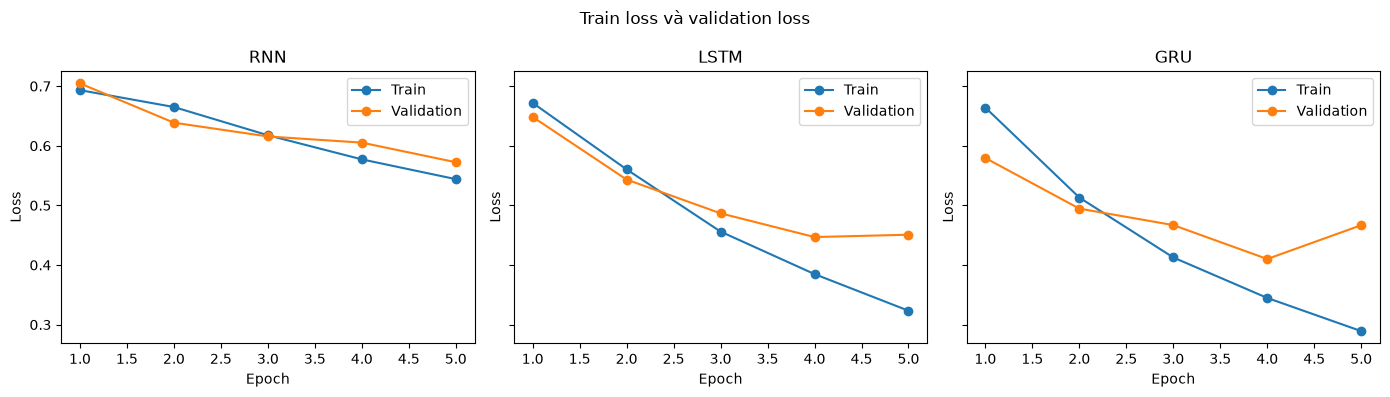

Đã lưu learning curves: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\learning_curves.png


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for axis, (name, run) in zip(
    axes,
    [("RNN", rnn_run), ("LSTM", lstm_run), ("GRU", gru_run)],
):
    history = run["history"]
    axis.plot(history["epoch"], history["train_loss"], marker="o", label="Train")
    axis.plot(
        history["epoch"],
        history["validation_loss"],
        marker="o",
        label="Validation",
    )
    axis.set_title(name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Loss")
    axis.legend()

fig.suptitle("Train loss và validation loss")
fig.tight_layout()
fig.savefig(LEARNING_CURVES_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu learning curves: {LEARNING_CURVES_PATH}")


**Nhận xét — Learning curves**

Train loss giảm ở cả ba model. RNN có validation loss giảm liên tục từ 0,7046 xuống 0,5724 trong 5 epoch, chưa thấy dấu hiệu overfitting rõ. Với LSTM, validation loss giảm tới 0,4469 ở epoch 4 rồi nhích lên 0,4508 ở epoch 5. Với GRU, validation loss giảm tới 0,4101 ở epoch 4 rồi tăng lên 0,4667 ở epoch 5 trong khi train loss tiếp tục giảm; đây là dấu hiệu overfitting rõ hơn ở epoch cuối. Cả hai checkpoint được chọn theo validation loss tại epoch 4.

## 17. Experiment 5 — Chọn kiến trúc recurrent bằng validation

Chọn kiến trúc recurrent có validation macro F1 cao nhất để giữ cố định trong thí nghiệm max_length. Đây là lựa chọn theo validation, không dùng test.

In [29]:
recurrent_names = [
    "RNN + Embedding",
    "LSTM + Embedding",
    "GRU + Embedding",
]
selected_recurrent_name = max(
    recurrent_names,
    key=lambda name: candidate_models[name]["validation_metrics"]["f1_macro"],
)
selected_recurrent = candidate_models[selected_recurrent_name]
selected_recurrent_architecture = selected_recurrent["architecture"]

print("Kiến trúc dùng cho Experiment 5/6:", selected_recurrent_architecture)
print("Chọn theo validation macro F1.")


Kiến trúc dùng cho Experiment 5/6: GRU
Chọn theo validation macro F1.


## 18. Experiment 5 — Sequence length 50

Giữ architecture đã chọn và các hyperparameters cố định; chỉ đổi max_length. Mỗi run chọn checkpoint theo validation loss, sau đó báo cáo test metrics theo yêu cầu đề.

In [30]:
length_50_run = train_sequence_model(
    selected_recurrent_architecture, max_length=50
)
length_50_test_loader = make_loaders(50)[2]
length_50_test_loss, length_50_test_metrics, _, _, _ = evaluate_sequence_model(
    length_50_run["model"],
    length_50_test_loader,
    nn.BCEWithLogitsLoss(),
)
length_50_retained = (
    100 * np.minimum(all_token_lengths, 50).sum() / total_original_tokens
)
sequence_length_results[50] = {
    "run": length_50_run,
    "test_metrics": length_50_test_metrics,
    "test_loss": length_50_test_loss,
    "tokens_retained_percent": length_50_retained,
}


Vòng 1/5 | loss train=0.6719 | loss validation=0.6198 | F1 macro validation=0.6666
Vòng 2/5 | loss train=0.5563 | loss validation=0.5354 | F1 macro validation=0.7299
Vòng 3/5 | loss train=0.4662 | loss validation=0.5211 | F1 macro validation=0.7338
Vòng 4/5 | loss train=0.4014 | loss validation=0.4996 | F1 macro validation=0.7625
Vòng 5/5 | loss train=0.3423 | loss validation=0.5657 | F1 macro validation=0.7679


## 19. Experiment 5 — Sequence length 100

Độ dài này trùng với lần train kiến trúc ở Experiment 4, nên dùng lại checkpoint thay vì train thêm lần nữa.

In [31]:
length_100_run = selected_recurrent["run"]
length_100_test_loader = make_loaders(100)[2]
length_100_test_loss, length_100_test_metrics, _, _, _ = evaluate_sequence_model(
    length_100_run["model"],
    length_100_test_loader,
    nn.BCEWithLogitsLoss(),
)
length_100_retained = (
    100 * np.minimum(all_token_lengths, 100).sum() / total_original_tokens
)
sequence_length_results[100] = {
    "run": length_100_run,
    "test_metrics": length_100_test_metrics,
    "test_loss": length_100_test_loss,
    "tokens_retained_percent": length_100_retained,
}


## 20. Experiment 5 — Sequence length 200

In [32]:
length_200_run = train_sequence_model(
    selected_recurrent_architecture, max_length=200
)
length_200_test_loader = make_loaders(200)[2]
length_200_test_loss, length_200_test_metrics, _, _, _ = evaluate_sequence_model(
    length_200_run["model"],
    length_200_test_loader,
    nn.BCEWithLogitsLoss(),
)
length_200_retained = (
    100 * np.minimum(all_token_lengths, 200).sum() / total_original_tokens
)
sequence_length_results[200] = {
    "run": length_200_run,
    "test_metrics": length_200_test_metrics,
    "test_loss": length_200_test_loss,
    "tokens_retained_percent": length_200_retained,
}


Vòng 1/5 | loss train=0.6254 | loss validation=0.5315 | F1 macro validation=0.7436
Vòng 2/5 | loss train=0.4744 | loss validation=0.4337 | F1 macro validation=0.8064
Vòng 3/5 | loss train=0.3704 | loss validation=0.3816 | F1 macro validation=0.8363
Vòng 4/5 | loss train=0.3078 | loss validation=0.3627 | F1 macro validation=0.8443
Vòng 5/5 | loss train=0.2515 | loss validation=0.3806 | F1 macro validation=0.8575


In [33]:
sequence_length_rows = []
for max_length in LENGTH_VALUES:
    result = sequence_length_results[max_length]
    run = result["run"]
    metrics = result["test_metrics"]
    length_row = make_result_row(
        f"{selected_recurrent_architecture} — max_length={max_length}",
        selected_recurrent_architecture,
        "Embedding + " + selected_recurrent_architecture,
        "test",
        metrics,
        max_length=max_length,
        validation_loss=run["validation_loss"],
        training_seconds=run["training_seconds"],
        epochs_trained=run["epochs_trained"],
        parameters=run["parameters"],
        vocabulary_size=VOCAB_SIZE,
        tokens_retained_percent=result["tokens_retained_percent"],
        peak_memory_mb=run["peak_memory_mb"],
        notes="So sánh sequence length theo yêu cầu Experiment 5.",
    )
    sequence_length_rows.append(length_row)

sequence_length_table = pd.DataFrame(sequence_length_rows)
display(sequence_length_table[[
    "max_length",
    "tokens_retained_percent",
    "validation_loss",
    "accuracy",
    "precision_positive",
    "recall_positive",
    "f1_macro",
    "peak_memory_mb",
    "training_time_seconds",
    "epochs_trained",
    "parameters",
]])


,max_length,tokens_retained_percent,validation_loss,accuracy,precision_positive,recall_positive,f1_macro,peak_memory_mb,training_time_seconds,epochs_trained,parameters
0,50,21.532926,0.499610,0.765430,0.759749,0.778983,0.765365,NaN,57.492661,5,1945025
1,100,41.593978,0.410057,0.811819,0.790585,0.850311,0.811491,NaN,157.923818,5,1945025
2,200,68.700560,0.362737,0.846813,0.879167,0.805505,0.846589,NaN,793.775903,5,1945025


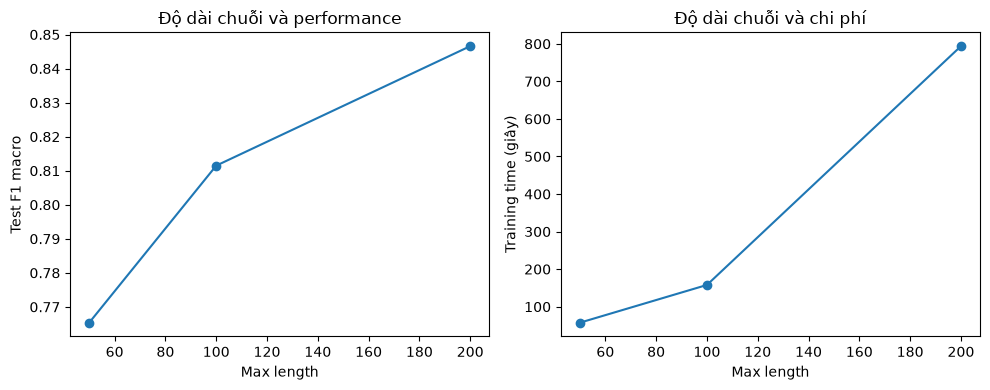

Đã lưu biểu đồ sequence length: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\sequence_length_experiment.png


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(
    sequence_length_table["max_length"],
    sequence_length_table["f1_macro"],
    marker="o",
)
axes[0].set_xlabel("Max length")
axes[0].set_ylabel("Test F1 macro")
axes[0].set_title("Độ dài chuỗi và performance")

axes[1].plot(
    sequence_length_table["max_length"],
    sequence_length_table["training_time_seconds"],
    marker="o",
)
axes[1].set_xlabel("Max length")
axes[1].set_ylabel("Training time (giây)")
axes[1].set_title("Độ dài chuỗi và chi phí")

fig.tight_layout()
fig.savefig(SEQUENCE_LENGTH_PLOT_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu biểu đồ sequence length: {SEQUENCE_LENGTH_PLOT_PATH}")


**Nhận xét — Experiment 5**

Ở các lần chạy này, test F1 macro tăng theo max_length: 0,7654 (50), 0,8115 (100), 0,8466 (200). Thời gian train cũng tăng mạnh: 57,5 giây, 157,9 giây và 793,8 giây. Độ dài 200 giữ 68,70% token so với 21,53% ở độ dài 50, nhưng mất khoảng 13,2 phút để train. Kết quả cho thấy trade-off rõ giữa lượng ngữ cảnh và chi phí tính toán; xu hướng này chỉ được quan sát trên các giá trị đã thử.

## 21. Experiment 6 — Vị trí từ mang sentiment

Tạo review ngắn có từ quyết định sentiment ở gần đầu, giữa hoặc cuối. Đây là quan sát trên ví dụ nhỏ; không dùng nó để khẳng định đã chứng minh vanishing gradient.

In [35]:
def make_position_probes():
    return [
        {
            "Vị trí": "Đầu",
            "Nhãn mong đợi": "positive",
            "Review": "Excellent is my verdict. Despite the slow opening, this movie kept my interest.",
        },
        {
            "Vị trí": "Giữa",
            "Nhãn mong đợi": "positive",
            "Review": "Despite the slow opening, this movie is excellent overall and kept my interest.",
        },
        {
            "Vị trí": "Cuối",
            "Nhãn mong đợi": "positive",
            "Review": "Despite the slow opening, this movie kept my interest; my verdict is excellent.",
        },
        {
            "Vị trí": "Đầu",
            "Nhãn mong đợi": "negative",
            "Review": "Terrible is my verdict. Despite a promising opening, this movie lost my interest.",
        },
        {
            "Vị trí": "Giữa",
            "Nhãn mong đợi": "negative",
            "Review": "Despite a promising opening, this movie is terrible overall and lost my interest.",
        },
        {
            "Vị trí": "Cuối",
            "Nhãn mong đợi": "negative",
            "Review": "Despite a promising opening, this movie lost my interest; my verdict is terrible.",
        },
    ]

position_probes = pd.DataFrame(make_position_probes())
display(position_probes[["Vị trí", "Nhãn mong đợi", "Review"]])


,Vị trí,Nhãn mong đợi,Review
0,Đầu,positive,Excellent is my verdict. Despite the slow open...
1,Giữa,positive,"Despite the slow opening, this movie is excell..."
2,Cuối,positive,"Despite the slow opening, this movie kept my i..."
3,Đầu,negative,Terrible is my verdict. Despite a promising op...
4,Giữa,negative,"Despite a promising opening, this movie is ter..."
5,Cuối,negative,"Despite a promising opening, this movie lost m..."


Dùng model recurrent đã chọn ở độ dài nền 100 để dự đoán các câu trên. Xác suất là điểm số model, không phải lời giải thích nhân quả cho quyết định.

In [36]:
def predict_with_sequence_model(model, review_list, max_length):
    encoded, lengths = encode_reviews(review_list, vocab, max_length)
    dataset = ReviewSequenceDataset(
        encoded,
        lengths,
        np.zeros(len(review_list), dtype=np.int64),
        max_length,
    )
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    model.eval()
    probabilities = []
    with torch.no_grad():
        for token_ids, batch_lengths, _ in loader:
            logits = model(token_ids.to(DEVICE), batch_lengths)
            probabilities.extend(torch.sigmoid(logits).cpu().tolist())
    return np.asarray(probabilities)

position_model = selected_recurrent["model"]
position_probabilities = predict_with_sequence_model(
    position_model,
    position_probes["Review"].tolist(),
    BASE_MAX_LENGTH,
)
position_probes["Xác suất positive"] = position_probabilities
position_probes["Dự đoán"] = np.where(
    position_probabilities >= 0.5, "positive", "negative"
)
display(position_probes)


,Vị trí,Nhãn mong đợi,Review,Xác suất positive,Dự đoán
0,Đầu,positive,Excellent is my verdict. Despite the slow open...,0.329269,negative
1,Giữa,positive,"Despite the slow opening, this movie is excell...",0.837202,positive
2,Cuối,positive,"Despite the slow opening, this movie kept my i...",0.648888,positive
3,Đầu,negative,Terrible is my verdict. Despite a promising op...,0.404732,negative
4,Giữa,negative,"Despite a promising opening, this movie is ter...",0.062668,negative
5,Cuối,negative,"Despite a promising opening, this movie lost m...",0.097493,negative


**Nhận xét — Experiment 6**

Quan sát: GRU dự đoán đúng 5/6 câu thử. Với từ tích cực ở đầu câu, xác suất positive là 0,329 nên bị dự đoán negative; khi từ tích cực ở giữa/cuối, xác suất lần lượt là 0,837 và 0,649. Cả ba câu có từ tiêu cực đều được dự đoán negative.

Giải thích: Đây là ví dụ nhỏ với câu chữ thay đổi theo vị trí, nên chỉ cho thấy prediction nhạy với ví dụ và vị trí từ trong lần thử này. Nó không chứng minh GRU nhớ dependency xa hay chứng minh vanishing gradient; muốn kết luận về cơ chế cần thí nghiệm kiểm soát chặt hơn.

## 22. Chọn model cuối bằng validation và đánh giá test

Chọn trong TF-IDF/RNN/LSTM/GRU theo validation macro F1. Sau khi chọn mới dùng test để báo cáo kết quả cuối và confusion matrix.

In [37]:
best_model_name = max(
    candidate_models,
    key=lambda name: candidate_models[name]["validation_metrics"]["f1_macro"],
)
best_candidate = candidate_models[best_model_name]
print("Model chọn theo validation macro F1:", best_model_name)

if best_candidate["kind"] == "tfidf":
    best_test_predictions = best_candidate["model"].predict(x_test)
    best_test_metrics = calculate_metrics(y_test, best_test_predictions)
    best_test_loss = np.nan
else:
    best_test_loader = make_loaders(BASE_MAX_LENGTH)[2]
    best_test_loss, best_test_metrics, _, best_test_predictions, _ = (
        evaluate_sequence_model(
            best_candidate["model"],
            best_test_loader,
            nn.BCEWithLogitsLoss(),
        )
    )

best_test_result = make_result_row(
    best_model_name,
    best_candidate["architecture"],
    (
        "TF-IDF unigram"
        if best_candidate["kind"] == "tfidf"
        else "Embedding + " + best_candidate["architecture"]
    ),
    "test",
    best_test_metrics,
    max_length=(
        np.nan if best_candidate["kind"] == "tfidf" else BASE_MAX_LENGTH
    ),
    validation_loss=(
        np.nan
        if best_candidate["kind"] == "tfidf"
        else best_candidate["run"]["validation_loss"]
    ),
    training_seconds=(
        tfidf_training_seconds
        if best_candidate["kind"] == "tfidf"
        else best_candidate["run"]["training_seconds"]
    ),
    epochs_trained=(
        np.nan
        if best_candidate["kind"] == "tfidf"
        else best_candidate["run"]["epochs_trained"]
    ),
    parameters=(
        tfidf_parameters
        if best_candidate["kind"] == "tfidf"
        else best_candidate["run"]["parameters"]
    ),
    peak_memory_mb=(
        np.nan
        if best_candidate["kind"] == "tfidf"
        else best_candidate["run"]["peak_memory_mb"]
    ),
    vocabulary_size=(
        tfidf_vocabulary_size
        if best_candidate["kind"] == "tfidf"
        else VOCAB_SIZE
    ),
    notes="Model được chọn theo validation macro F1.",
)
display(pd.DataFrame([best_test_result]))


Model chọn theo validation macro F1: TF-IDF + Logistic Regression


,model,architecture,representation,max_length,split,accuracy,precision_positive,recall_positive,f1_positive,f1_macro,validation_loss,training_time_seconds,epochs_trained,parameters,vocabulary_size,tokens_retained_percent,peak_memory_mb,notes
0,TF-IDF + Logistic Regression,Logistic Regression,TF-IDF unigram,NaN,test,0.894917,0.884352,0.909584,0.896791,0.894883,NaN,6.139227,NaN,82647,82646,NaN,NaN,Model được chọn theo validation macro F1.


,Dự đoán: negative,Dự đoán: positive
Thật: negative,4347,592
Thật: positive,450,4527


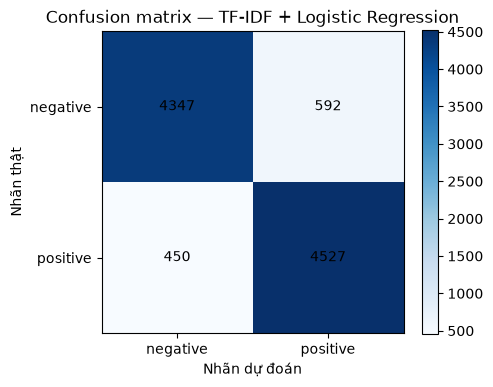

Đã lưu confusion matrix: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\confusion_matrix.png


In [38]:
label_ids = [0, 1]
matrix = confusion_matrix(
    y_test,
    best_test_predictions,
    labels=label_ids,
)
confusion_table = pd.DataFrame(
    matrix,
    index=["Thật: negative", "Thật: positive"],
    columns=["Dự đoán: negative", "Dự đoán: positive"],
)
display(confusion_table)

fig, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(matrix, cmap="Blues")
axis.set_xticks([0, 1], labels=["negative", "positive"])
axis.set_yticks([0, 1], labels=["negative", "positive"])
axis.set_xlabel("Nhãn dự đoán")
axis.set_ylabel("Nhãn thật")
axis.set_title(f"Confusion matrix — {best_model_name}")
for row in range(2):
    for column in range(2):
        axis.text(
            column,
            row,
            str(matrix[row, column]),
            ha="center",
            va="center",
        )
fig.colorbar(image, ax=axis)
fig.tight_layout()
fig.savefig(CONFUSION_MATRIX_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu confusion matrix: {CONFUSION_MATRIX_PATH}")


**Nhận xét — Evaluation**

Confusion matrix có 4.347 negative dự đoán đúng, 592 negative bị nhầm thành positive, 4.527 positive dự đoán đúng và 450 positive bị nhầm thành negative. False positive nhiều hơn false negative 142 mẫu. Accuracy test là 0,8949 và macro F1 là 0,8949, rất gần nhau; điều này phù hợp với phân phối lớp gần cân bằng (positive 50,19%, negative 49,81%).

## 23. Error analysis — ví dụ đúng và sai

Lấy ít nhất 3 ví dụ mỗi nhóm từ test. Phần dưới bảng phân tích các ví dụ sai theo ngữ cảnh, phủ định và cảm xúc pha trộn; xem xét liệu có bằng chứng liên quan sequence modeling không.

In [39]:
test_examples = pd.DataFrame({
    "Text": x_test,
    "True": np.where(np.asarray(y_test) == 1, "positive", "negative"),
    "Predicted": np.where(
        np.asarray(best_test_predictions) == 1, "positive", "negative"
    ),
})
test_examples["Correct"] = test_examples["True"] == test_examples["Predicted"]

correct_examples = test_examples[test_examples["Correct"]].sample(
    n=min(3, int(test_examples["Correct"].sum())),
    random_state=RANDOM_STATE,
)
incorrect_examples = test_examples[~test_examples["Correct"]].sample(
    n=min(3, int((~test_examples["Correct"]).sum())),
    random_state=RANDOM_STATE,
)

print("Ví dụ phân loại đúng")
display(correct_examples[["Text", "True", "Predicted"]])
print("Ví dụ phân loại sai")
incorrect_examples_for_notes = incorrect_examples[
    ["Text", "True", "Predicted"]
].copy()
incorrect_examples_for_notes["Analysis (tự điền)"] = ""
display(incorrect_examples_for_notes)


Ví dụ phân loại đúng


,Text,True,Predicted
6495,this is one of the funniest movies i've ever s...,positive,positive
9115,"an inventive, suspenseful exercise in claustro...",positive,positive
8751,"this film is really really bad, it is not very...",negative,negative


Ví dụ phân loại sai


,Text,True,Predicted,Analysis (tự điền)
5199,"okay, i'll admit that if i didn't have kids, i...",positive,negative,
8209,i could not take my eyes off this movie when i...,positive,negative,
4682,"when it came out, this was pretty much state o...",positive,negative,


## 24. Application — thử review mới

Thử review ngắn, dài, có negation và có contrast. Xem phần nhận xét sau bảng để đối chiếu prediction với nội dung review.

In [40]:
application_reviews = [
    {
        "Loại": "Ngắn",
        "Review": "I loved this movie.",
    },
    {
        "Loại": "Dài",
        "Review": (
            "The film starts slowly and spends a long time introducing its characters. "
            "The performances are convincing, the story becomes more interesting, "
            "and the ending feels satisfying. I enjoyed watching it."
        ),
    },
    {
        "Loại": "Negation",
        "Review": "I did not like this movie.",
    },
    {
        "Loại": "Contrast",
        "Review": "I expected the movie to be terrible, but it was surprisingly good.",
    },
]

def predict_new_reviews(review_list):
    if best_candidate["kind"] == "tfidf":
        positive_probability = best_candidate["model"].predict_proba(
            review_list
        )[:, 1]
    else:
        positive_probability = predict_with_sequence_model(
            best_candidate["model"],
            review_list,
            BASE_MAX_LENGTH,
        )
    return positive_probability

application_table = pd.DataFrame(application_reviews)
application_probabilities = predict_new_reviews(
    application_table["Review"].tolist()
)
application_table["Xác suất positive"] = application_probabilities
application_table["Dự đoán"] = np.where(
    application_probabilities >= 0.5, "positive", "negative"
)
application_table["Từ/ngữ cảnh ảnh hưởng (tự ghi)"] = ""
display(application_table)


,Loại,Review,Xác suất positive,Dự đoán,Từ/ngữ cảnh ảnh hưởng (tự ghi)
0,Ngắn,I loved this movie.,0.969612,positive,
1,Dài,The film starts slowly and spends a long time ...,0.781352,positive,
2,Negation,I did not like this movie.,0.097021,negative,
3,Contrast,"I expected the movie to be terrible, but it wa...",0.188152,negative,


**Nhận xét thử application**

Model cuối được chọn là TF-IDF + Logistic Regression. Review ngắn I loved this movie được dự đoán positive với xác suất 0,970; review dài được dự đoán positive với xác suất 0,781. Câu phủ định I did not like this movie được dự đoán negative với xác suất positive 0,097.

Câu contrast I expected the movie to be terrible, but it was surprisingly good lại bị dự đoán negative (xác suất positive 0,188), dù ý cuối câu tích cực. Một khả năng là unigram không giữ quan hệ chuyển ý sau but và từ terrible tạo tín hiệu âm; đây là giải thích khả dĩ, không phải attribution trực tiếp từ model.

## 25. Lưu kết quả

Lưu validation của các candidate, test của model cuối và test F1 theo sequence length. Nhận xét đã ghi ở các phần tương ứng trong notebook, reflection.md và error_analysis.md.

In [41]:
validation_result_rows = [
    candidate["validation_row"]
    for candidate in candidate_models.values()
]
final_result_rows = (
    validation_result_rows
    + sequence_length_rows
    + [best_test_result]
)
results_df = pd.DataFrame(final_result_rows)
results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8-sig")

display(results_df)
print(f"Đã lưu bảng kết quả: {RESULTS_PATH}")
print("Các biểu đồ được lưu tại:")
print(f"- {LEARNING_CURVES_PATH}")
print(f"- {SEQUENCE_LENGTH_PLOT_PATH}")
print(f"- {CONFUSION_MATRIX_PATH}")


,model,architecture,representation,max_length,split,accuracy,precision_positive,recall_positive,f1_positive,f1_macro,validation_loss,training_time_seconds,epochs_trained,parameters,vocabulary_size,tokens_retained_percent,peak_memory_mb,notes
0,TF-IDF + Logistic Regression,Logistic Regression,TF-IDF unigram,NaN,validation,0.894010,0.884450,0.907374,0.895765,0.893980,NaN,6.139227,NaN,82647,82646,NaN,NaN,Fit vectorizer chỉ trên train.
1,RNN + Embedding,RNN,Embedding + RNN,100.0,validation,0.731444,0.726774,0.745027,0.735787,0.731372,0.572370,64.466036,5.0,1928385,30000,41.593978,NaN,Best checkpoint ở epoch 5.
2,LSTM + Embedding,LSTM,Embedding + LSTM,100.0,validation,0.797398,0.804348,0.788025,0.796103,0.797390,0.446856,306.712128,5.0,1953345,30000,41.593978,NaN,Best checkpoint ở epoch 4.
3,GRU + Embedding,GRU,Embedding + GRU,100.0,validation,0.816559,0.795030,0.854933,0.823894,0.816240,0.410057,157.923818,5.0,1945025,30000,41.593978,NaN,Best checkpoint ở epoch 4.
4,GRU — max_length=50,GRU,Embedding + GRU,50.0,test,0.765430,0.759749,0.778983,0.769246,0.765365,0.499610,57.492661,5.0,1945025,30000,21.532926,NaN,So sánh sequence length theo yêu cầu Experimen...
5,GRU — max_length=100,GRU,Embedding + GRU,100.0,test,0.811819,0.790585,0.850311,0.819361,0.811491,0.410057,157.923818,5.0,1945025,30000,41.593978,NaN,So sánh sequence length theo yêu cầu Experimen...
6,GRU — max_length=200,GRU,Embedding + GRU,200.0,test,0.846813,0.879167,0.805505,0.840726,0.846589,0.362737,793.775903,5.0,1945025,30000,68.700560,NaN,So sánh sequence length theo yêu cầu Experimen...
7,TF-IDF + Logistic Regression,Logistic Regression,TF-IDF unigram,NaN,test,0.894917,0.884352,0.909584,0.896791,0.894883,NaN,6.139227,NaN,82647,82646,NaN,NaN,Model được chọn theo validation macro F1.


Đã lưu bảng kết quả: C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\results.csv
Các biểu đồ được lưu tại:
- C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\learning_curves.png
- C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\sequence_length_experiment.png
- C:\Users\KIEN\OneDrive\Máy tính\NLP\lab05\confusion_matrix.png
